In [1]:
import torch
from transformers import GPT2LMHeadModel, GPT2TokenizerFast
import torch.nn.functional as F

tokenizer = GPT2TokenizerFast.from_pretrained("gpt2")
model = GPT2LMHeadModel.from_pretrained("gpt2").eval()

def score_tokens_perplexity(text: str) -> dict:
    ids = tokenizer(text, return_tensors="pt").input_ids
    with torch.no_grad():
        logits = model(ids).logits
    log_probs = F.log_softmax(logits, dim=-1)
    token_lp = log_probs[0, :-1].gather(1, ids[0, 1:].unsqueeze(1)).squeeze()
    surprisal = -token_lp
    tokens = [tokenizer.decode([t]) for t in ids[0, 1:]]
    return {"tokens": tokens, "surprisal": surprisal.tolist()}


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

In [2]:
import random

def compress_random(text: str, ratio: float) -> str:
    tokens = tokenizer.tokenize(text)
    k = max(1, int(len(tokens) * ratio))
    kept = sorted(random.sample(range(len(tokens)), k))
    return tokenizer.convert_tokens_to_string([tokens[i] for i in kept])

In [3]:
def compress_perplexity(text: str, ratio: float) -> str:
    result = score_tokens_perplexity(text)
    tokens, scores = result["tokens"], result["surprisal"]
    k = max(1, int(len(tokens) * ratio))
    top_idx = sorted(sorted(range(len(scores)), key=lambda i: scores[i], reverse=True)[:k])
    return "".join([tokens[i] for i in top_idx])


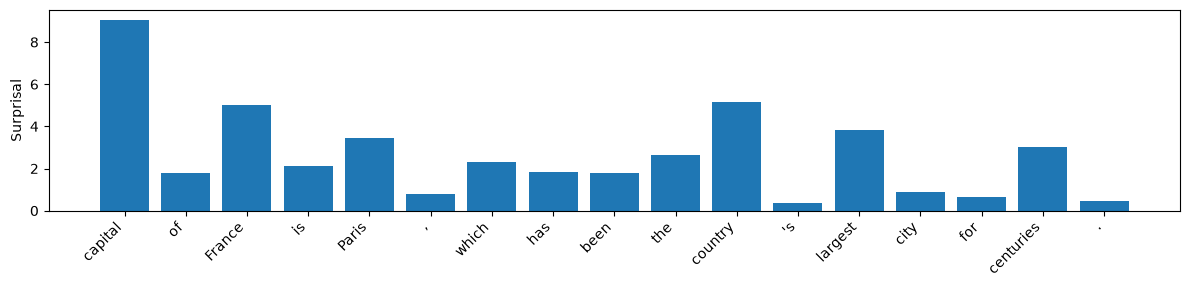

In [4]:

import matplotlib.pyplot as plt

sample = "The capital of France is Paris, which has been the country's largest city for centuries."
r = score_tokens_perplexity(sample)
plt.figure(figsize=(12, 3))
plt.bar(range(len(r["tokens"])), r["surprisal"])
plt.xticks(range(len(r["tokens"])), r["tokens"], rotation=45, ha="right")
plt.ylabel("Surprisal"); plt.tight_layout(); plt.show()